# Frequency-search results explorer

Look at the output of an adversarial frequency search (`freq_search.py`): the
per-`(letter, pattern)` multipliers, the resulting per-word frequencies, and the
greedy strategy analyzed the *same way* as in `strategy_explorer` but under the
adversarial weighting (greedy playing against the adversarial word choices).

Generate a run first with e.g. `python math/freq_search.py 5` (saves to
`math/data/freq_search/len05.csv`); this notebook loads it back.

In [1]:
from pathlib import Path
import sys

def find_math_dir():
    cwd = Path.cwd().resolve()
    for c in (cwd, cwd.parent, cwd.parent.parent, cwd / 'math', cwd.parent / 'math'):
        if (c / 'freq_search.py').exists():
            return c
    raise FileNotFoundError('Could not find freq_search.py. Open from the repo root, math/, or math/notebooks/.')

math_dir = find_math_dir()
if str(math_dir) not in sys.path:
    sys.path.insert(0, str(math_dir))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import freq_search, strategy

print(f'imported from {math_dir}')

imported from /Users/patrickliscio/My Documents/Pycharm Projects/Ballpark-Figures/hangman/math


## Load a search result

Loads the saved CSV for this length if present; otherwise runs one inline (which
can be slow for larger lengths).

In [2]:
LENGTH = 4
OBJECTIVE = 'greedy'      # 'greedy' or 'best_opener' -- which tuned run to explore below

csv_path = freq_search._default_log_path(OBJECTIVE, LENGTH)
if csv_path.exists():
    s = freq_search.FrequencySearch.reconstruct(LENGTH, csv_path, objective=OBJECTIVE)
    print(f'loaded {OBJECTIVE} run: {csv_path.parent.name}/{csv_path.name}')
else:
    print(f'no saved run at {csv_path}\nrunning one inline (may take a while)...')
    s = freq_search.FrequencySearch(LENGTH, objective=OBJECTIVE)
    s.run(verbose=False)

game, f = s.game, s.freq
bo_letter, bo = game.best_opener_misses(f)
print(f'length {LENGTH} [{OBJECTIVE}]: {game.N} words, {s.M} patterns')
print(f'on this tuned distribution -- pure greedy {game.average_misses(f):.4f}   '
      f'best opener {bo:.4f} (via {bo_letter!r})')

loaded greedy run: freq_search/len04.csv
length 4 [greedy]: 2120 words, 167 patterns
on this tuned distribution -- pure greedy 6.9062   best opener 6.5441 (via 't')


## Compare objectives: greedy-tuned vs best-opener-tuned

Load **both** adversarial runs for this length (if present) and score each tuned
distribution with **both** guessers: `greedy_avg` = pure greedy, `best_opener_avg`
= the guesser who picks the best first letter then plays greedy. A distribution
tuned only against *pure greedy* can be escaped by a smarter opener (large `gap`);
one tuned against the *best-opener* guesser leaves little room to improve (small
`gap`). Missing runs are skipped — generate them with `python math/freq_search.py
<LEN>` and `... --best-opener`.

In [3]:
def load_run(objective):
    p = freq_search._default_log_path(objective, LENGTH)
    if not p.exists():
        print(f'  (no {objective!r} run for length {LENGTH} at {p.parent.name}/{p.name})')
        return None
    return freq_search.FrequencySearch.reconstruct(LENGTH, p, objective=objective)

# score each tuned distribution with BOTH guessers
rows = []
for objective in freq_search.OBJECTIVES:
    r = load_run(objective)
    if r is None:
        continue
    gm, fr = r.game, r.freq
    greedy = gm.average_misses(fr)
    bl, bv = gm.best_opener_misses(fr)
    rows.append({'tuned_for': objective,
                 'greedy_avg': greedy, 'greedy_opener': gm.greedy_first_letter(fr),
                 'best_opener_avg': bv, 'best_opener_letter': bl,
                 'gap': greedy - bv})
pd.DataFrame(rows).set_index('tuned_for').round(4)

,greedy_avg,greedy_opener,best_opener_avg,best_opener_letter,gap
tuned_for,,,,,
greedy,6.9062,a,6.5441,t,0.3621
best_opener,6.8619,e,6.7965,i,0.0654


## Multipliers

One row per `(letter, pattern)`; `multiplier` is the tuned weight, `n_words` how
many words carry that pattern.

In [4]:
mult_df = s.multipliers_df()
print(f'{(mult_df.multiplier == 0).sum()} patterns of {len(mult_df)} zeroed; '
      f'{(mult_df.multiplier > 1).sum()} boosted above 1; '
      f'max multiplier {mult_df.multiplier.max():g}')
mult_df.head(50)

51 patterns of 167 zeroed; 34 boosted above 1; max multiplier 11.375


,letter,pattern,mask,multiplier,n_words
0,v,___v,8,11.375,3
1,z,___z,8,7.500,3
2,j,__jj,12,6.500,1
3,z,__zz,12,6.125,4
4,t,__tt,12,4.750,4
5,f,f_f_,5,4.625,1
6,x,__x_,4,4.500,9
7,f,__ff,12,4.000,12
8,b,b_b_,5,4.000,3
9,m,_m_m,10,4.000,1


In [5]:
mult_df[mult_df['pattern'] == '____s']

,letter,pattern,mask,multiplier,n_words


In [6]:
mult_df.tail(50)

,letter,pattern,mask,multiplier,n_words
117,s,s_s_,5,0.0,1
118,l,l_l_,5,0.0,3
119,l,l_ll,13,0.0,1
120,f,_ff_,6,0.0,2
121,i,i_i_,5,0.0,2
122,s,s_ss,13,0.0,1
123,o,__oo,12,0.0,1
124,u,_u_u,10,0.0,3
125,o,oo__,3,0.0,1
126,n,__nn,12,0.0,1


## Frequencies

One row per word (frequency = product of its pattern multipliers).

In [7]:
freq_df = s.frequencies_df()
print(f'{(freq_df.frequency == 0).sum()} words of {len(freq_df)} at frequency 0 (removed); '
      f'heaviest carry the adversarial weight:')
freq_df.head(50)

840 words of 2120 at frequency 0 (removed); heaviest carry the adversarial weight:


,word,frequency
0,jeez,15.000
1,hajj,13.000
2,jazz,12.250
3,buzz,12.250
4,fizz,12.250
5,fuzz,12.250
6,perv,11.375
7,noon,10.500
8,putt,9.500
9,watt,9.500


In [8]:
freq_df.tail(50)

,word,frequency
2070,unto,0.0
2071,trek,0.0
2072,toes,0.0
2073,stir,0.0
2074,eyed,0.0
2075,slap,0.0
2076,whit,0.0
2077,clan,0.0
2078,prey,0.0
2079,oval,0.0


## Uniform baseline + the two guessers on the tuned distribution

Each cell compares three lenses:

- **uniform** — every word equally likely (`freq=None`), pure greedy — the
  "normal game" baseline (the original `strategy_explorer` view);
- **pure greedy** — on the tuned distribution `f`, opens with its highest
  combined-frequency letter (`go`);
- **best opener** — on `f`, forces the single best first letter (`bo_letter`).

The greedy↔best-opener gap on `f` is exactly what the `best_opener` search targets.

uniform     : avg 5.4778  (opens 'e')
pure greedy : avg 6.9062  (opens 'a')
best opener : avg 6.5441  (opens 't')


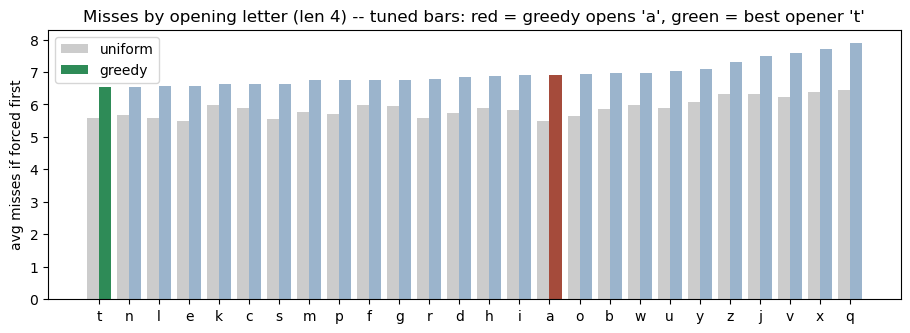

,t,n,l,e,k,c,s,m,p,f,...,o,b,w,u,y,z,j,v,x,q
uniform,5.570755,5.673585,5.579245,5.47783,5.998585,5.880660,5.553774,5.771226,5.718868,5.970283,...,5.630660,5.863208,5.976415,5.897170,6.085377,6.332547,6.334906,6.228774,6.384434,6.449528
greedy,6.544146,6.548936,6.569446,6.57626,6.634302,6.639721,6.645345,6.743126,6.748282,6.768758,...,6.952819,6.969133,6.981400,7.025563,7.102971,7.293892,7.505745,7.581164,7.712568,7.906243


In [9]:
# the three lenses: uniform baseline, then the two guessers on the tuned distribution
go = game.greedy_first_letter(f)                 # greedy's opener on f
print(f'uniform     : avg {game.average_misses(None):.4f}  (opens {game.greedy_first_letter(None)!r})')
print(f'pure greedy : avg {game.average_misses(f):.4f}  (opens {go!r})')
print(f'best opener : avg {bo:.4f}  (opens {bo_letter!r})')

# Mode B -- misses if each letter is forced first: uniform vs the tuned distribution;
# the tuned bars mark greedy's opener (red) and the best opener (green)
mbu = pd.Series(game.misses_by_starting_letter(None))
mba = pd.Series(game.misses_by_starting_letter(f))
order = list(mba.sort_values().index)
x = np.arange(len(order)); w = 0.4
adv_colors = ['#9bb4cc'] * len(order)
adv_colors[order.index(go)] = '#a54b3b'          # red = greedy opens here
adv_colors[order.index(bo_letter)] = '#2e8b57'   # green = best opener
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.bar(x - w / 2, mbu[order].values, w, label='uniform', color='#cccccc')
ax.bar(x + w / 2, mba[order].values, w, label=OBJECTIVE, color=adv_colors)
ax.set_xticks(x); ax.set_xticklabels(order)
ax.set_ylabel('avg misses if forced first'); ax.legend()
ax.set_title(f'Misses by opening letter (len {LENGTH}) -- tuned bars: '
             f'red = greedy opens {go!r}, green = best opener {bo_letter!r}')
plt.show()
pd.DataFrame({'uniform': mbu[order], OBJECTIVE: mba[order]}).T

## Per-word difficulty: uniform vs greedy vs best opener

All three lenses, frequency-weighted (uniform weights each word equally; the two
tuned lenses weight by `f`; each normalized to a share of total weight).

weighted avg misses -- uniform 5.4778   pure greedy 6.9062   best opener 6.5441


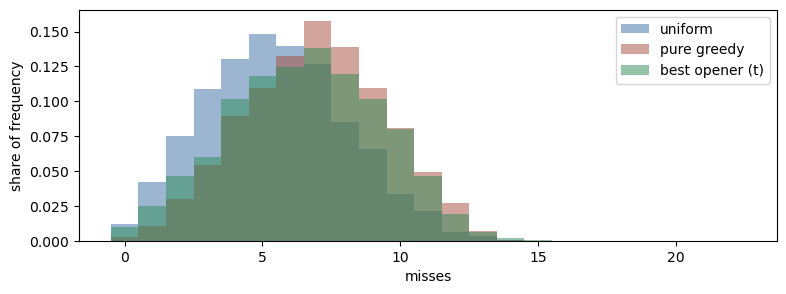

hardest words (pure greedy) under this distribution:


,word,freq,misses_uniform,misses_greedy,misses_best_opener
0,eyes,0.0,2,22,22
1,says,0.0,5,21,21
2,exes,0.0,1,21,21
3,flex,0.0,7,20,20
4,clay,0.0,8,20,20
5,whew,0.0,4,20,20
6,axed,0.0,5,20,20
7,flax,0.0,9,20,20
8,whey,0.0,5,20,20
9,year,0.0,10,20,20


In [10]:
upm = game.per_word_misses(None)                 # uniform baseline (pure greedy)
gpm = game.per_word_misses(f)                    # pure greedy on the tuned distribution
bpm = game.per_word_misses(f, opener=bo_letter)  # best opener on the tuned distribution
words = pd.DataFrame({'word': game.words, 'freq': f,
                      'misses_uniform':     upm.astype(int),
                      'misses_greedy':      gpm.astype(int),
                      'misses_best_opener': bpm.astype(int)})

print(f'weighted avg misses -- uniform {game.average_misses(None):.4f}   '
      f'pure greedy {game.average_misses(f):.4f}   best opener {bo:.4f}')

bins = range(0, int(max(upm.max(), gpm.max(), bpm.max())) + 2)
fig, ax = plt.subplots(figsize=(9, 3))
for pwm, wt, name, color in [(upm, None, 'uniform',                    '#3b6ea5'),
                             (gpm, f,    'pure greedy',                '#a54b3b'),
                             (bpm, f,    f'best opener ({bo_letter})', '#2e8b57')]:
    ax.hist(pwm, bins=bins, weights=wt, density=True,
            alpha=0.5, label=name, color=color, align='left')
ax.set_xlabel('misses'); ax.set_ylabel('share of frequency'); ax.legend()
plt.show()

print('hardest words (pure greedy) under this distribution:')
words.sort_values('misses_greedy', ascending=False).head(15).reset_index(drop=True)

In [11]:
# The adversary zeros out many words (freq 0) -- those don't count toward its
# average. Hardest words it actually KEEPS (nonzero frequency), with both guessers:
kept = words[words.freq > 0]
print(f'{len(kept)} of {len(words)} words kept (nonzero frequency)')
kept.sort_values('misses_greedy', ascending=False).head(15).reset_index(drop=True)

1280 of 2120 words kept (nonzero frequency)


,word,freq,misses_uniform,misses_greedy,misses_best_opener
0,sane,1.000,10,14,14
1,sage,1.000,8,13,13
2,zest,0.250,9,13,11
3,sent,0.500,7,13,11
4,sill,2.000,6,13,15
5,ween,2.000,9,13,10
6,very,1.000,11,13,8
7,sale,0.875,7,13,13
8,labs,1.000,8,13,13
9,soot,1.750,9,13,8


## Trace a word: uniform vs greedy vs best opener

The guess sequence for one word under each lens (`+` = hit, `-` = miss). On the
tuned distribution greedy opens with `go` and the best-opener guesser with
`bo_letter`; the uniform lens is the normal-game baseline.

In [12]:
# hardest word (pure greedy) the adversary actually KEEPS; or set WORD = 'bench'
nz = np.flatnonzero(f > 0)
WORD = game.words[nz[gpm[nz].argmax()]]
print(WORD)
for name, fr, kw in [('uniform', None, {}),
                     (f'greedy (opens {go})',      f, {}),
                     (f'best opener (opens {bo_letter})', f, {'opener': bo_letter})]:
    hits = game.trace(WORD, fr, **kw)
    seq = '  '.join(f'{l}{"+" if h else "-"}' for l, h in hits)
    print(f'{name:>26}  ({sum(1 for _, h in hits if not h)} misses):  {seq}')

sane
                   uniform  (10 misses):  e+  a+  m-  l-  r-  v-  t-  c-  b-  g-  d-  n+  p-  s+
          greedy (opens a)  (14 misses):  a+  e+  c-  k-  m-  v-  t-  r-  b-  z-  l-  p-  d-  w-  s+  f-  g-  n+
     best opener (opens t)  (14 misses):  t-  a+  e+  c-  k-  m-  v-  r-  b-  z-  l-  p-  d-  w-  s+  f-  g-  n+
